# Module 8 - DSA 7010: Principles of Data Science - Final Project Story 

You have made it to the end of the course, and you have worked hard to develop your DSA perspectives and skills.  So far we have been internally focused on the operations of performing data science and analytics.  Now we will extend our work to the development of a data story that is externally focused.

In the Module 8 labs, you saw simplified examples of constructing data stories. Throughout the course, there are components and parts useful to consider as a basis for developing a short, unique, focused data story.


For this final project, you will 

- Step 0: Choose your Language for this Adventure

- Step 1: Find a Story

- Step 2: Remember your Audience

- Step 3: Find and Stage Your Data

- Step 4: Vet Data Sources

- Step 5: Filter Results and Build/Validate Models

- Step 6: Visualize Results

- Step 7: Communicate the Story to your intended audience using visualizations and narratives

- Step 8: Connect your workflow/process to the DSA-Project Life Cycle

- Step 9: Post your story's abstract with an appropriate visualization to Canvas

---
Here are some recommendations for managing the scope and quality of this project:

- Narrow down the issue, problem, question, or hypothesis for your data story to a single, relatively simple perspective.

- Identify what aspects or attributes from the provided data that affords addressing your problem.  If incorporating another, completely new, data set - explain it as well.

- Address the data relative to the statistical/machine learning model(s) chosen to minimize any issues.

- Internally document your code using comments and markdown cells that explain the purpose of the operation(s) as well as interpreting the results of those operations.


You can make your project more unique by:

- Comparing two or more different statistical / machine learning models using the same data.
- Refrain from identically replicating any existing projects obtained from external sources or in class collaborations - this should be your idea and analysis!
- Running a single model multiple times and changing a different single parameter each time for comparison.
- Changing the sampling proportions for building the hold-out data and comparing the same model performance repeatedly.
- Select something you find interesting or unique in the data and write an analytical story around it.




## Step 0: Choose your Language for this Adventure:

I Will be working with R for this project.


---
## Step 1: Find a Question / Story   (5 points)

Think about the data file that has been provided for this project to use in this class. 
Additionally, you can search online for potential data to incorporate **with** the provided data to support the story idea.

In the cell below, please detail the source of any additional data (with link) as welll as preview the data story you hope to uncover.

---

### Title: Does education level influence Covid-19 vaccination rates accross Missouri counties?
 The aim of this project is to find out whether the levels of educational attainment influence COVID-19 vaccination rates among Missouri counties. Fot this project, i will be making use of the Missouri County Data provided. Variables like percentage of adults with a bachelor’s degree (P_EDUC_Bac) and lower than high school education (P_EDUC_LTH) will be analysed to determine their relationship with the percent of fully vaccinated residents (PctCOVFull).

Hypothesis and Expected Outcomes:

Existing hypothesis suggests that higher educational levels among counties will lead to higher COVID-19 vaccination rates. It is expected that education plays a crucial role in shaping public-health behaviours within counties because it influences individuals access to information, trust in scientific guidance, critical thinking skills.Counties with lower educational levels might encounter limitations like misinformation, lower health literacy, limited access to healthcare which can in turn reduce vaccine uptake.

This project will harness decision tree, linear regression to uncover actionable insights that might be usefult to public-health officials and policy makers. The anticipated outcome is a clear, data-supported demonstration that educational attainment is a strong predictor of vaccination behavior in Missouri.

**Data Sources:**

* Primary dataset: MO_County_Data_CSV_DSA7010_Project_Data.csv (provided in course materials).
* Secondary dataset: U.S. counties dataset Built_in in the maps package in R.

**Data fields of interest:**
* cnty_name (county names)

* PctCOVFull (percent fully vaccinated)

* PctCOV1Dos (percent with at least one vaccine dose)

* P_EDUC_Bac (percent with bachelor’s degree)

* P_EDUC_LTH (percent less than high school)

* E_MEDINC (median income)

* P_Disab (percent with disability)

* Obesity, SmokePrev2 (health behaviors)

## Step 2: Remember your Audience  (5 points)

In the cell below, describe the audience for this analysis!
 * Who will the audience be?
 * What value will they derive from your story?

---
My primary audience are policymakers, missouri education advocates, public health officials. My secondary audience are healthcare providers, educational research organisations that are focused on vaccination behaviour, county-level health departments. 

THe value derived:
 Missouri public health officials and decision makers will be able t identify counties where vaccination uptake is influenced by loc educational levels. The analytical findings can also help to promotr targeted public health campaigns and educational outreach programmes that is aimed towards health literacy and improving vaccination coverage accross counties.

## Step 3: Find and Stage Your Data   (10 points)

If you incorporate data from another source, you must download it to your local computer, then upload the data to JuptyerHub.

#### If you are uploading files:
 * Use folder navigation of your first JupyterTab to get to course's `/modules/module8/exercises/` folder.
![FP_Folder_Navigation.png MISSING](../images/FP_Folder_Navigation.png)
 * Click the Upload Button and Choose File(s)
![FP_Upload_Button.png MISSING](../images/FP_Upload_Button.png)
 * Activate the upload
![FP_UploadFile_2.png MISSING](../images/FP_UploadFile_2.png)
 

### In the cell below, please list the name(s) of the file(s) that are now accessible on the JupyterHub environment.

**Note** 
If you uploaded a file to your `module8/exercises` folder, the file name is all you need to load it into the data frame in the usual manner.
If you are using a file from another module of the course, you should be able to copy the full pathname and use it as is in this notebook.
The full pathname has been provided for the Missouri County-based data that has been provided.  Be sure to include it below as well!!!

Missouri County Data: /f25dsa7010_cm98m/module8/exercises/myData/MO_County_data.csv
U.S county map dataset in_built in R maps package.

In [1]:
#Load libraries
library(tidyverse)     
library(caret)         
library(randomForest) 
install.packages("corrplot")
library(corrplot)      
library(dplyr) 
library(stringr)
install.packages("maps")
library(maps)
library(ggplot2)
library("sf")
library("plotly")
library(viridis)


── Attaching packages ─────────────────────────────────────── tidyverse 1.2.1 ──
✔ ggplot2 3.2.1     ✔ purrr   0.3.2
✔ tibble  2.1.3     ✔ dplyr   0.8.3
✔ tidyr   1.0.0     ✔ stringr 1.4.0
✔ readr   1.3.1     ✔ forcats 0.4.0
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
Loading required package: lattice

Attaching package: ‘caret’

The following object is masked from ‘package:purrr’:

    lift

randomForest 4.6-14
Type rfNews() to see new features/changes/bug fixes.

Attaching package: ‘randomForest’

The following object is masked from ‘package:dplyr’:

    combine

The following object is masked from ‘package:ggplot2’:

    margin

Updating HTML index of packages in '.Library'
Making 'packages.html' ... done
corrplot 0.95 loaded
Updating HTML index of packages in '.Library'
Making 'packages.html' ... done

Attaching package: ‘maps’

The following object is masked from ‘pack

For this project, i will be using the *MO county dataset* already provided. I will also be using the U.S county map dataset in_built in R maps package.


## Step 4: Explore and Vet your Data Sources  (15 points)

Use the cells below to load the data, inspect it, conduct data carpentry and shaping; perform exploratory data analysis.  

Add more cells (`Insert > Insert Cell Below`) if you want additional cells.  Also add cells that help visualize your exploration and what you found and how those findings directed your story.

In [2]:
# Load data 
df <- read.csv("/dsa/home/cm98m/jupyter/f25dsa7010_cm98m/module8/exercises/myData/MO_County_Data.csv", header = TRUE, stringsAsFactors = FALSE)


# Select needed variables
df <- df %>%
  select(cnty_name,
         PctCOVFull,
         PctCOV1Dos,
         P_EDUC_Bac,
         P_EDUC_LTH,
         E_MEDINC,
         P_Disab,
         Obesity,
         SmokePrev2)

# Inspect data
glimpse(df)
summary(df)

head(df)

Observations: 115
Variables: 9
$ cnty_name  <chr> "Adair", "Andrew", "Atchison", "Audrain", "Barry", "Barton…
$ PctCOVFull <dbl> 0.35, 0.28, 0.40, 0.28, 0.33, 0.25, 0.29, 0.37, 0.25, 0.50…
$ PctCOV1Dos <dbl> 0.39, 0.31, 0.45, 0.33, 0.40, 0.29, 0.34, 0.42, 0.28, 0.56…
$ P_EDUC_Bac <dbl> 30.0, 23.8, 22.5, 14.5, 14.5, 18.1, 14.9, 13.4, 9.4, 46.0,…
$ P_EDUC_LTH <dbl> 9.4, 8.1, 9.4, 14.5, 17.8, 12.8, 13.3, 14.1, 20.6, 5.8, 11…
$ E_MEDINC   <int> 19948, 30332, 27793, 23528, 22485, 23325, 26697, 21236, 22…
$ P_Disab    <dbl> 16.4, 17.3, 22.0, 20.3, 22.0, 21.4, 20.2, 29.2, 28.4, 13.7…
$ Obesity    <dbl> 28.2, 31.3, 39.3, 35.3, 38.5, 25.3, 36.8, 34.0, 32.1, 26.3…
$ SmokePrev2 <dbl> 23.3, 24.4, 22.8, 28.8, 28.3, 27.0, 29.9, 28.8, 28.2, 18.0…


  cnty_name           PctCOVFull       PctCOV1Dos       P_EDUC_Bac   
 Length:115         Min.   :0.1400   Min.   :0.1800   Min.   : 9.40  
 Class :character   1st Qu.:0.2450   1st Qu.:0.2900   1st Qu.:13.65  
 Mode  :character   Median :0.3000   Median :0.3400   Median :16.50  
                    Mean   :0.2962   Mean   :0.3441   Mean   :18.36  
                    3rd Qu.:0.3400   3rd Qu.:0.3950   3rd Qu.:20.10  
                    Max.   :0.5000   Max.   :0.5600   Max.   :46.00  
   P_EDUC_LTH       E_MEDINC        P_Disab         Obesity     
 Min.   : 4.70   Min.   :15665   Min.   :12.20   Min.   :21.00  
 1st Qu.:10.95   1st Qu.:22066   1st Qu.:18.00   1st Qu.:30.00  
 Median :13.00   Median :24422   Median :21.00   Median :33.20  
 Mean   :13.87   Mean   :24903   Mean   :21.78   Mean   :33.01  
 3rd Qu.:16.25   3rd Qu.:26630   3rd Qu.:25.35   3rd Qu.:36.20  
 Max.   :25.50   Max.   :39869   Max.   :37.90   Max.   :46.30  
   SmokePrev2   
 Min.   :18.00  
 1st Qu.:25.90  
 Med

cnty_name,PctCOVFull,PctCOV1Dos,P_EDUC_Bac,P_EDUC_LTH,E_MEDINC,P_Disab,Obesity,SmokePrev2
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>
Adair,0.35,0.39,30.0,9.4,19948,16.4,28.2,23.3
Andrew,0.28,0.31,23.8,8.1,30332,17.3,31.3,24.4
Atchison,0.40,0.45,22.5,9.4,27793,22.0,39.3,22.8
Audrain,0.28,0.33,14.5,14.5,23528,20.3,35.3,28.8
Barry,0.33,0.40,14.5,17.8,22485,22.0,38.5,28.3
Barton,0.25,0.29,18.1,12.8,23325,21.4,25.3,27.0


For readability, I will rename all the column names for easy readability and i'll make them all lowercase with unserscores.

In [3]:
# Rename columns for readability

df <- df %>%
  rename(
    county = cnty_name,
    pct_fully_vaccinated = PctCOVFull,
    pct_one_dose = PctCOV1Dos,
    pct_bachelors = P_EDUC_Bac,
    pct_less_than_high_school = P_EDUC_LTH,
    median_income = E_MEDINC,
    pct_disability = P_Disab,
    obesity_rate = Obesity,
    smoking_prevalence = SmokePrev2
  )


glimpse(df)


Observations: 115
Variables: 9
$ county                    <chr> "Adair", "Andrew", "Atchison", "Audrain", "…
$ pct_fully_vaccinated      <dbl> 0.35, 0.28, 0.40, 0.28, 0.33, 0.25, 0.29, 0…
$ pct_one_dose              <dbl> 0.39, 0.31, 0.45, 0.33, 0.40, 0.29, 0.34, 0…
$ pct_bachelors             <dbl> 30.0, 23.8, 22.5, 14.5, 14.5, 18.1, 14.9, 1…
$ pct_less_than_high_school <dbl> 9.4, 8.1, 9.4, 14.5, 17.8, 12.8, 13.3, 14.1…
$ median_income             <int> 19948, 30332, 27793, 23528, 22485, 23325, 2…
$ pct_disability            <dbl> 16.4, 17.3, 22.0, 20.3, 22.0, 21.4, 20.2, 2…
$ obesity_rate              <dbl> 28.2, 31.3, 39.3, 35.3, 38.5, 25.3, 36.8, 3…
$ smoking_prevalence        <dbl> 23.3, 24.4, 22.8, 28.8, 28.3, 27.0, 29.9, 2…


I'll check for any missing values in each row and column.

In [4]:
# Check missing values per column
colSums(is.na(df))



county      pct_fully_vaccinated              pct_one_dose 
                        0                         0                         0 
            pct_bachelors pct_less_than_high_school             median_income 
                        0                         0                         0 
           pct_disability              obesity_rate        smoking_prevalence 
                        0                         0                         0

In [5]:
# Remove rows with missing target for or key education variables

before_count <- nrow(df)

df <- df %>%
  filter(
    !is.na(pct_fully_vaccinated) &
    !is.na(pct_bachelors) &
    !is.na(pct_less_than_high_school &
    !is.na(pct_one_dose))
  )

after_count <- nrow(df)

# Calculate how many were removed
removed_count <- before_count - after_count

# Print summary
cat("Rows before filtering:", before_count, "\n")
cat("Rows after filtering:", after_count, "\n")
cat("Rows removed due to missing values:", removed_count, "\n")

Rows before filtering: 115 
Rows after filtering: 115 
Rows removed due to missing values: 0 


I will convert the pct_fully_vaccinated	and pct_one_dose to percentages for easy visualisation. I'll accomplish this by multiplyting the column by 100.

In [6]:

df <- df %>%
  mutate(
    pct_fully_vaccinated = pct_fully_vaccinated * 100,
    pct_one_dose = pct_one_dose * 100
  )
head(df[, c("pct_fully_vaccinated", "pct_one_dose")])

pct_fully_vaccinated,pct_one_dose
<dbl>,<dbl>
35,39
28,31
40,45
28,33
33,40
25,29


Next, I want to make sure there are no stray text values in numeric columns, no duplicates, and the structure is tidy.

In [7]:
# Ensure numeric columns are properly typed
df <- df %>%
  mutate(
    pct_fully_vaccinated = as.numeric(pct_fully_vaccinated),
    pct_one_dose = as.numeric(pct_one_dose),
    pct_bachelors = as.numeric(pct_bachelors),
    pct_less_than_high_school = as.numeric(pct_less_than_high_school),
    median_income = as.numeric(median_income),
    pct_disability = as.numeric(pct_disability),
    obesity_rate = as.numeric(obesity_rate),
    smoking_prevalence = as.numeric(smoking_prevalence)
  )
head(df)

county,pct_fully_vaccinated,pct_one_dose,pct_bachelors,pct_less_than_high_school,median_income,pct_disability,obesity_rate,smoking_prevalence
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Adair,35,39,30.0,9.4,19948,16.4,28.2,23.3
Andrew,28,31,23.8,8.1,30332,17.3,31.3,24.4
Atchison,40,45,22.5,9.4,27793,22.0,39.3,22.8
Audrain,28,33,14.5,14.5,23528,20.3,35.3,28.8
Barry,33,40,14.5,17.8,22485,22.0,38.5,28.3
Barton,25,29,18.1,12.8,23325,21.4,25.3,27.0


### Exploratory Data analysis
#### Univariate Analysis

Lets visualise some variables to reveals skewness, outliers, or unusual distributions in vaccination and education levels.

`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.
`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.


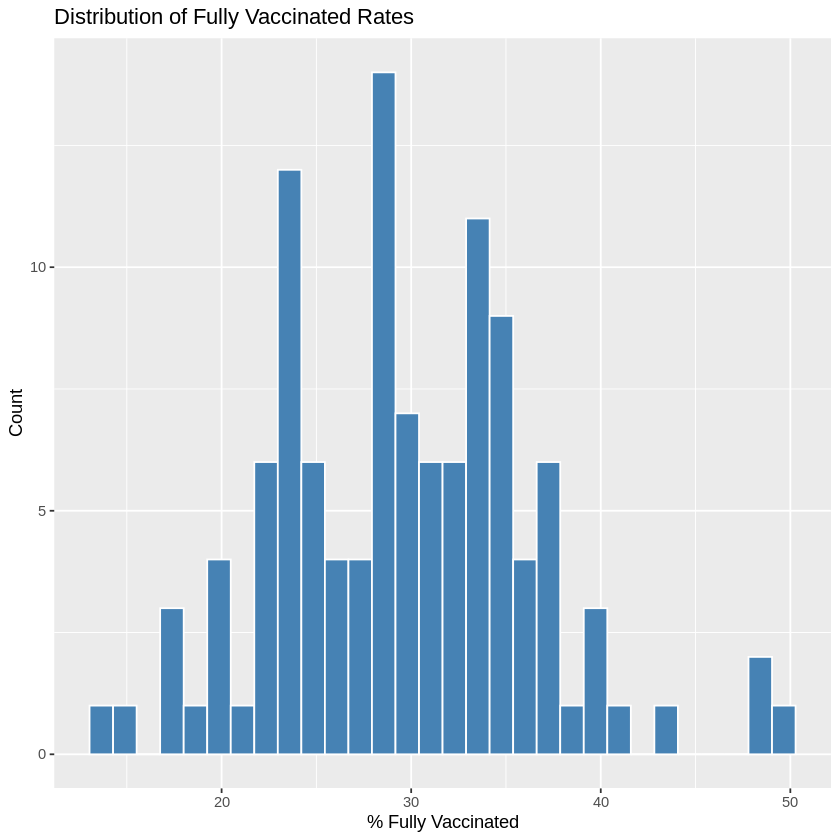

`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.


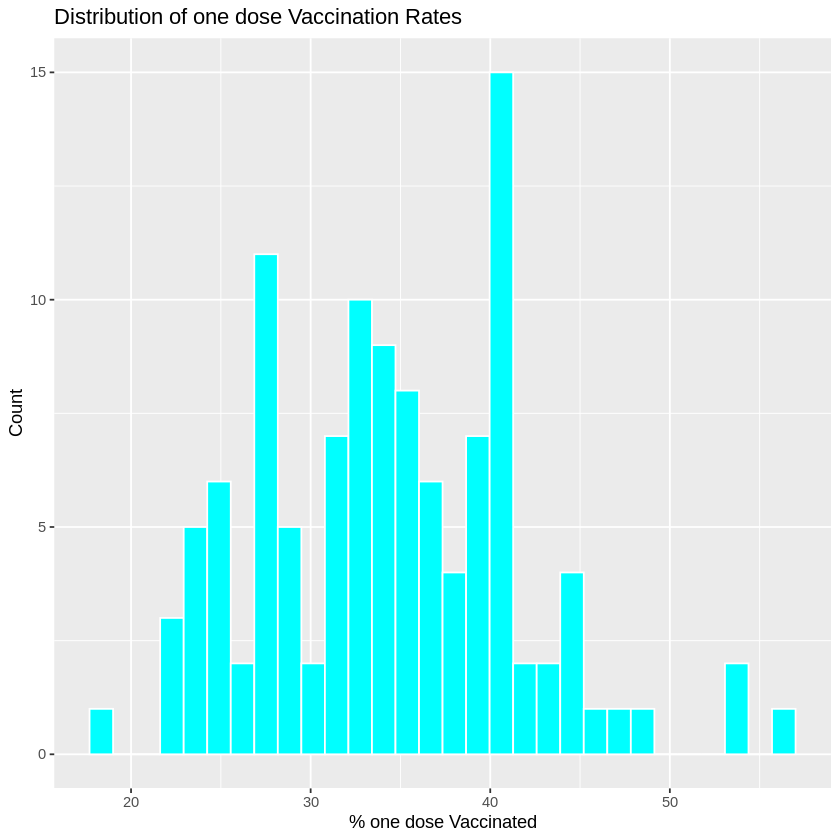

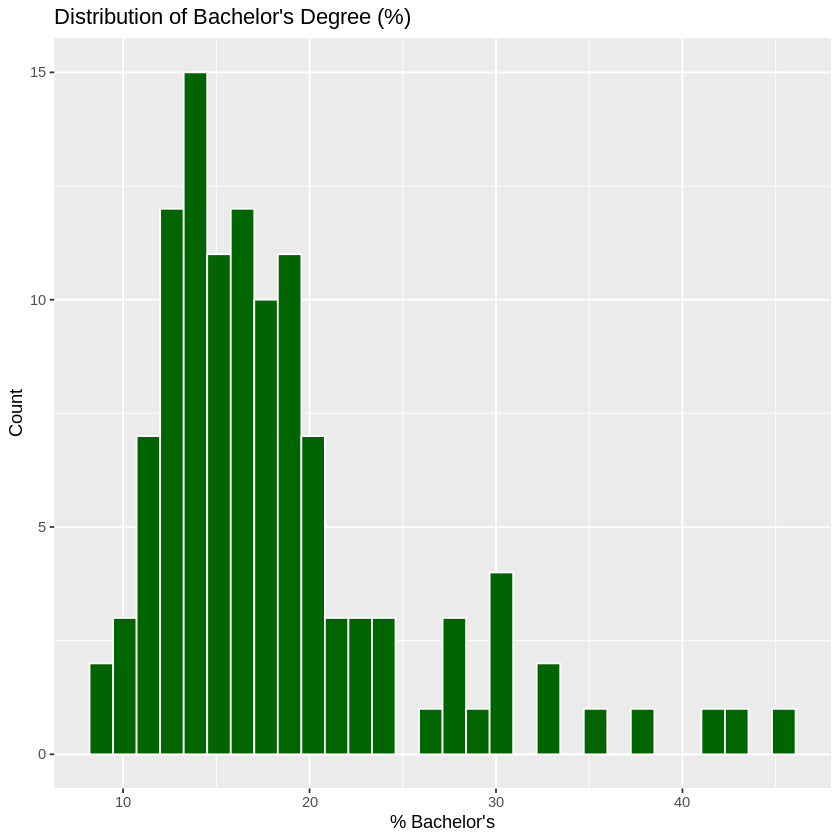

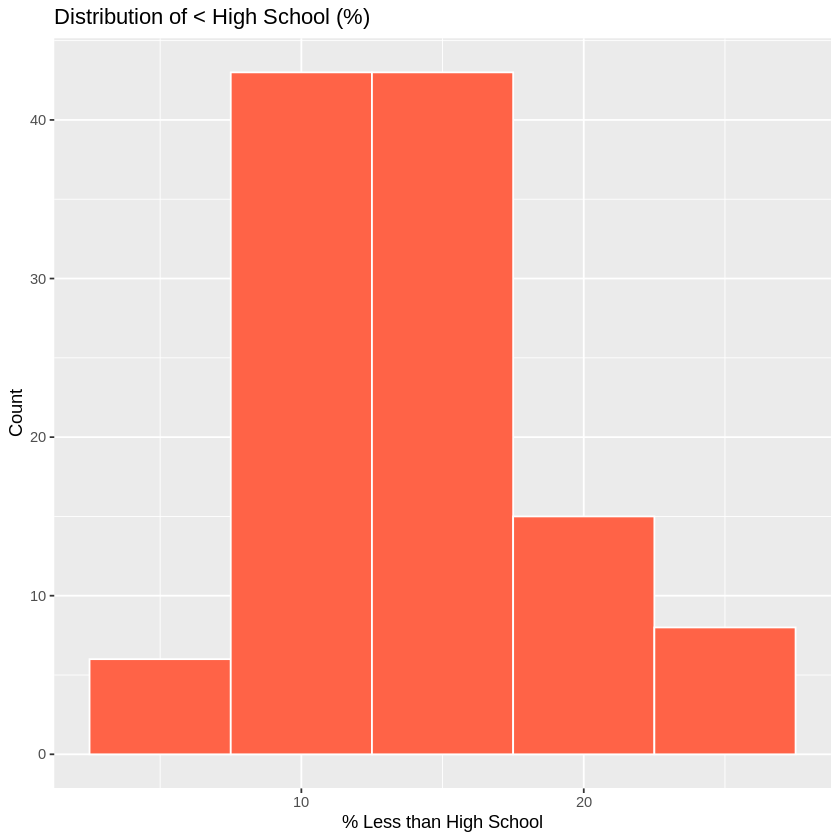

In [8]:
# Histogram for vaccination rate
ggplot(df, aes(x = pct_fully_vaccinated)) +
  geom_histogram(fill = "steelblue", color = "white") +
  labs(title = "Distribution of Fully Vaccinated Rates", x = "% Fully Vaccinated", y = "Count")

ggplot(df, aes(x = pct_one_dose)) +
  geom_histogram(fill = "cyan", color = "white") +
  labs(title = "Distribution of one dose Vaccination Rates", x = "% one dose Vaccinated", y = "Count")

# Histogram for education variables
ggplot(df, aes(x = pct_bachelors)) +
  geom_histogram (fill = "darkgreen", color = "white") +
  labs(title = "Distribution of Bachelor's Degree (%)", x = "% Bachelor's", y = "Count")

ggplot(df, aes(x = pct_less_than_high_school)) +
  geom_histogram(binwidth = 5, fill = "tomato", color = "white") +
  labs(title = "Distribution of < High School (%)", x = "% Less than High School", y = "Count")


The histograms above shows pct_fully_vaccinated and pct_less_than_high_school showed a relatively normal distribution, pct_one_dose and pct_bachelors did not show a normal disstribution. pct_bachelots is right skewed which entails that more people in most of the counties hold a bachelors degree.

Now I want to see the top ten counties with high full dose vaccinations and the top 10 counties with bachelors degree.

In [9]:
top10_vaccination <- df %>%
  arrange(desc(pct_fully_vaccinated)) %>%
  select(county, pct_fully_vaccinated) %>%
  head(10)

top10_vaccination


county,pct_fully_vaccinated
<chr>,<dbl>
Boone,50
St. Charles,49
St. Louis County,48
Franklin,44
Cole,41
Atchison,40
Gasconade,40
Greene,40
Christian,39


In [10]:
top10_bach <- df %>%
  arrange(desc(pct_bachelors)) %>%
  select(county, pct_bachelors) %>%
  head(10)   # get top 10 rows
top10_bach

county,pct_bachelors
<chr>,<dbl>
Boone,46.0
St. Louis County,43.2
Platte,41.6
St. Charles,37.8
St. Louis City,35.0
Cole,32.9
Clay,32.7
Jackson,30.9
Cape Girardeau,30.6


In [11]:
onedose_vaccination <- df %>%
  arrange(desc(pct_one_dose)) %>%
  select(county, pct_one_dose) %>%
  head(10)

onedose_vaccination 


county,pct_one_dose
<chr>,<dbl>
Boone,56
St. Charles,54
St. Louis County,54
Franklin,49
Cole,47
Gasconade,46
Atchison,45
Christian,45
Greene,45


From the analysis above, Boone, St Charles, St Lousi, Cole and Greene county seems to be consistent among the top 10 counties with a bachelors degree, one dose and full vaccination.

#### Bivariate Analysis

Lets do some bivariate analysis to investigate the relationship between educational level and vaccination

In [12]:
# RElationship between BAchelors degree and full dose vaccination.
bac_vac<- df %>%
  arrange(desc(pct_fully_vaccinated)) %>%
  select(county, pct_bachelors, pct_fully_vaccinated)

head(bac_vac, 10L)


county,pct_bachelors,pct_fully_vaccinated
<chr>,<dbl>,<dbl>
Boone,46.0,50
St. Charles,37.8,49
St. Louis County,43.2,48
Franklin,20.1,44
Cole,32.9,41
Atchison,22.5,40
Gasconade,18.9,40
Greene,30.2,40
Christian,28.2,39


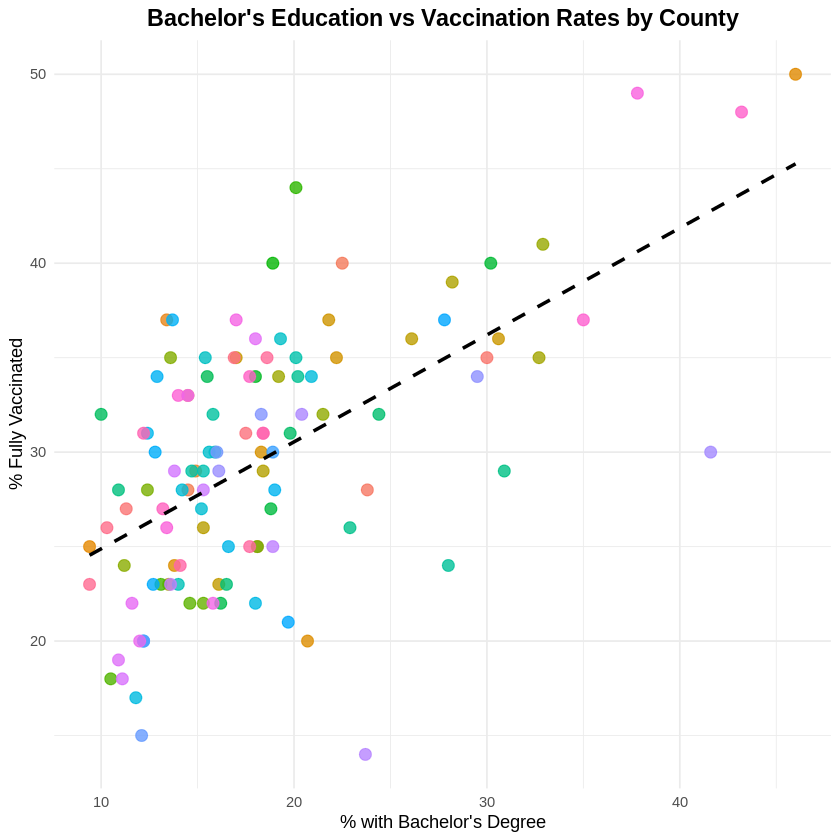

In [13]:
library(ggplot2)

# Scatterplot: Bachelor's vs Vaccination, colored by county
ggplot(bac_vac, aes(x = pct_bachelors, y = pct_fully_vaccinated, color = county)) +
  geom_point(alpha = 0.8, size = 3) +
  geom_smooth(method = "lm", se = FALSE, color = "black", linetype = "dashed") +
  labs(
    title = "Bachelor's Education vs Vaccination Rates by County",
    x = "% with Bachelor's Degree",
    y = "% Fully Vaccinated",
    color = "County"
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold", size = 14),
    legend.position = "none"
  )


The scatterplot ablove shows an obvious strong relationship between Bachelors degree education and full dose vaccination. The higher the level of education the higher the level of full COVID-19 vaccination. Lets investigate if those with less than gigh school education are fully vaccinated.

In [14]:
# RElationship between less than high school degree and full dose vaccination.
lth_vac <- df %>%
  arrange(desc(pct_less_than_high_school)) %>%
  select(county, pct_less_than_high_school, pct_fully_vaccinated)

head(lth_vac, 10L)


county,pct_less_than_high_school,pct_fully_vaccinated
<chr>,<dbl>,<dbl>
Mississippi,25.5,31
Wayne,24.7,26
Dunklin,24.5,23
McDonald,23.5,17
Washington,23.3,23
Crawford,22.9,24
Pemiscot,22.9,15
Scotland,22.9,20
New Madrid,22.0,23


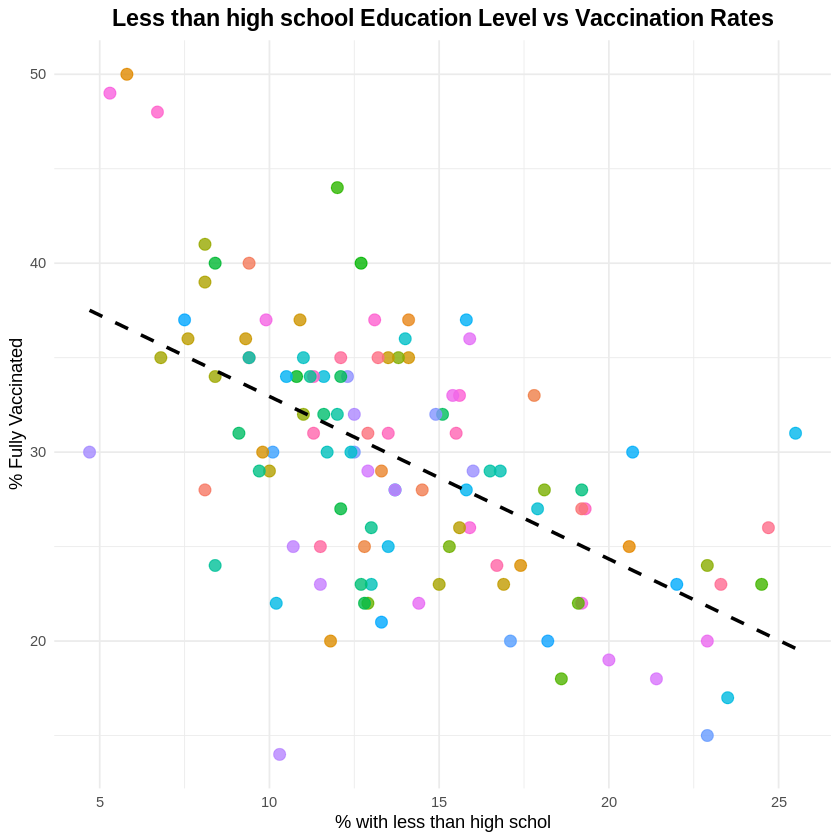

In [15]:
# Scatterplot:less than high school vs Vaccination, colored by county
ggplot(lth_vac, aes(x = pct_less_than_high_school, y = pct_fully_vaccinated, color = county)) +
  geom_point(alpha = 0.8, size = 3) +
  geom_smooth(method = "lm", se = FALSE, color = "black", linetype = "dashed") +
  labs(
     title = "Less than high school Education Level vs Vaccination Rates",
    x = "% with less than high schol",
    y = "% Fully Vaccinated",
    color = "County"
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold", size = 14),
    legend.position = "none"
  )


The analysis above shows that a less than high school education does not have any influence on vaccination rate as it depicts a negative linear relatinship. Now does less than high school education have any influence on even just one dose of vaccination?
Lets plot and visualise the relationship.

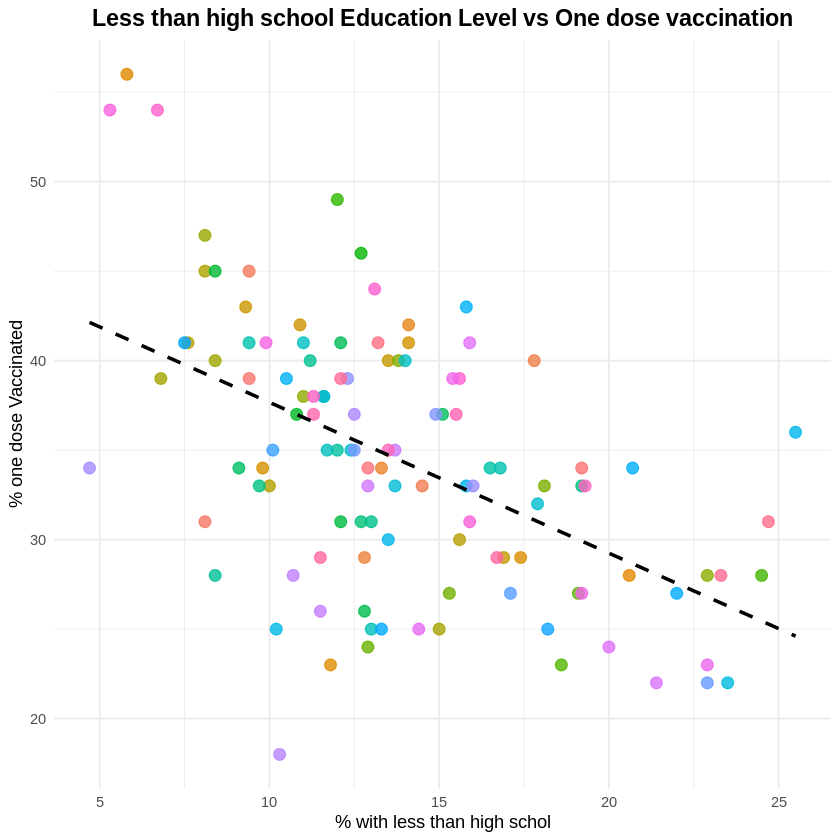

In [16]:
# Scatterplot:less than high school vs one dose Vaccination, colored by county
ggplot(df, aes(x = pct_less_than_high_school, y = pct_one_dose, color = county)) +
  geom_point(alpha = 0.8, size = 3) +
  geom_smooth(method = "lm", se = FALSE, color = "black", linetype = "dashed") +
  labs(
     title = "Less than high school Education Level vs One dose vaccination",
    x = "% with less than high schol",
    y = "% one dose Vaccinated",
    color = "County"
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold", size = 14),
    legend.position = "none"
  )

There is a very obvious negative linear relationship between less than high school education and even the one dose vaccination.

## Step 5: Filter Results and Build and Validate Models  (20 points)


Perform any additional data carpentry and begin filtering results/data and then build, validate, and describe your model(s). Make sure to provide interpretations of results and analytics!!!

Add more cells (`Insert > Insert Cell Below`) if you want additional cells.

### Correlation-Based Feature Selection

Firstly, I will check the correlation between the independent variables and the dependendent variables.

In [17]:
# Select data and find out correlation

data_model <- df %>%
  select(
    pct_fully_vaccinated,
    pct_bachelors,
    pct_less_than_high_school,
    median_income,
    pct_disability,
    obesity_rate,
    smoking_prevalence
  ) %>%
  na.omit()  # drop missing values if any

correlations <- cor(data_model)
round(correlations["pct_fully_vaccinated", ], 2)



pct_fully_vaccinated             pct_bachelors pct_less_than_high_school 
                     1.00                      0.59                     -0.57 
            median_income            pct_disability              obesity_rate 
                     0.50                     -0.53                     -0.02 
       smoking_prevalence 
                    -0.54

It is very clear that there is a strong correlation between pct_bachelors and pct_fully_vaccinated. Just for further analytic purposes, I will also use random forest to perform feature selection.

#### Recursive feature elimination

In [18]:
library(caret)

# Define predictors and target
X <- data_model %>% select(-pct_fully_vaccinated)
y <- data_model$pct_fully_vaccinated

# Set up control for RFE
control <- rfeControl(functions = lmFuncs, method = "cv", number = 10)

# Run RFE
set.seed(123)
rfe_results <- rfe(
  X,
  y,
  sizes = c(1:ncol(X)),   # try different numbers of features
  rfeControl = control
)

# View results
rfe_results



Recursive feature selection

Outer resampling method: Cross-Validated (10 fold) 

Resampling performance over subset size:

 Variables  RMSE Rsquared   MAE RMSESD RsquaredSD  MAESD Selected
         1 5.855   0.2876 4.721  1.093     0.1616 0.7722         
         2 5.608   0.3465 4.459  1.176     0.1926 0.9004         
         3 5.464   0.3735 4.342  1.100     0.1707 0.8389        *
         4 5.525   0.3523 4.410  1.011     0.1581 0.8280         
         5 5.496   0.3620 4.376  1.016     0.1525 0.8303         
         6 5.535   0.3569 4.411  1.046     0.1594 0.8539         

The top 3 variables (out of 3):
   pct_less_than_high_school, pct_bachelors, pct_disability


rfe identified the top three variables with the strongest correlation whether negative or positive to pct_fully_vaccinated as pct_less_than_high_school, pct_bachelors, pct_disability. Lets visualise.

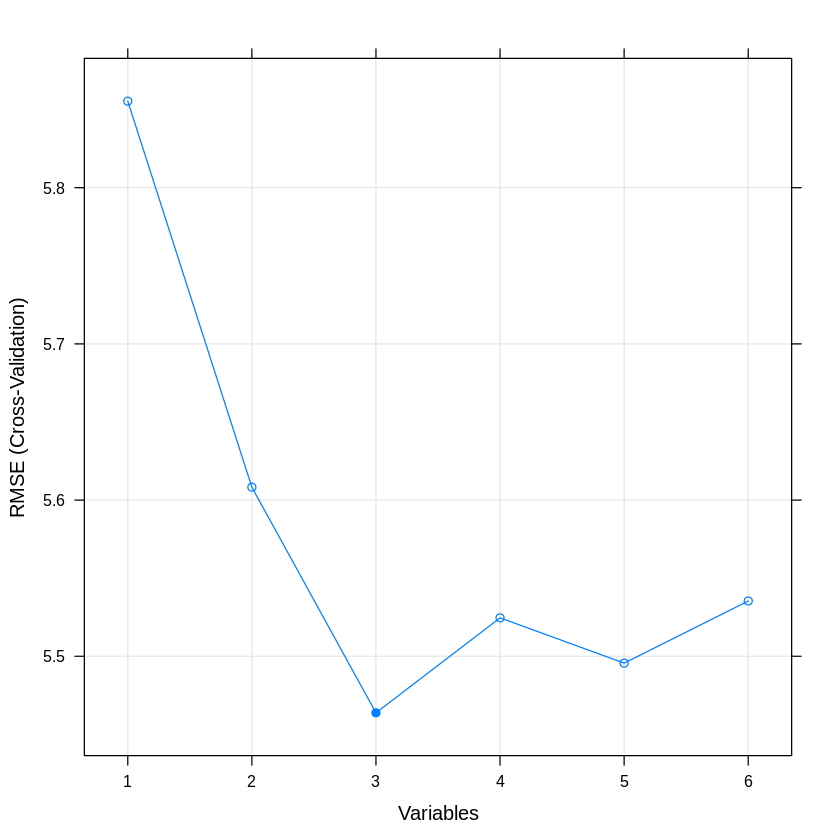

In [19]:
plot(rfe_results, type = c("g", "o"))


### Random forest model

,%IncMSE,IncNodePurity
pct_bachelors,9.102564,1005.1792
pct_less_than_high_school,14.550115,990.5673
median_income,5.436620,689.7380
pct_disability,12.032988,908.4938
obesity_rate,1.318175,461.8486
smoking_prevalence,9.680301,890.8675


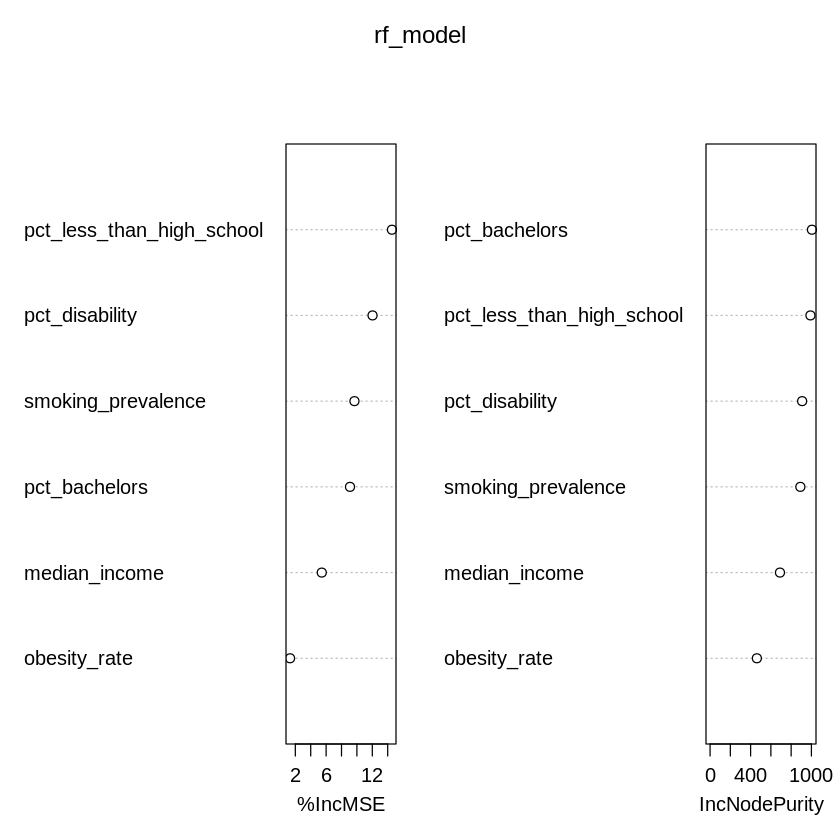

In [20]:
library(randomForest)

set.seed(123)
rf_model <- randomForest(
  pct_fully_vaccinated ~ .,
  data = data_model,
  importance = TRUE
)

importance(rf_model)
varImpPlot(rf_model)


Based on the random forest method, it is clear that Bachelors degree level of education has a strong effect on vaccination rate. Now lets train our model based on this. To train this model I will harness the use of Linear regression as well as Decision tree model.

In [21]:
# Prepare the data
bachelors_data <- df %>%
  select(
    pct_fully_vaccinated,
    pct_bachelors
  ) %>%
  na.omit()


In [22]:
# Split the data into training tset and testing set
set.seed(123)

n <- nrow(bachelors_data)
train_index <- sample(1:n, size = 0.7 * n)

train_data <- bachelors_data[train_index, ]
test_data  <- bachelors_data[-train_index, ]


#### Linear regression model

In [23]:
# linear regression model
lm_model_bac <- lm(
  pct_fully_vaccinated ~ pct_bachelors,
  data = train_data
)

summary(lm_model_bac)



Call:
lm(formula = pct_fully_vaccinated ~ pct_bachelors, data = train_data)

Residuals:
     Min       1Q   Median       3Q      Max 
-18.7982  -4.0013   0.6473   4.1447  10.8302 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)   17.54640    1.74418  10.060 9.68e-16 ***
pct_bachelors  0.64354    0.08714   7.385 1.44e-10 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 5.738 on 78 degrees of freedom
Multiple R-squared:  0.4115,	Adjusted R-squared:  0.404 
F-statistic: 54.55 on 1 and 78 DF,  p-value: 1.443e-10


an R² = 0.41 → The model explains ~41% of the variability in vaccination rates across counties using only bachelor’s degree % as a predictor.

Residual Std. Error ≈ 5.74 → Predictions are typically within ±5.7 percentage points of actual values.

F-statistic is large and highly significant → The model fits much better than a horizontal line (no relationship).

This is a strong relationship for a single predictor in real-world social data — education level alone explains nearly half of the variation in vaccination rates.

In [ ]:
# Extract intercepts and slope

intcpt <- coef(lm_model_bac)[1]  # intercept
slp    <- coef(lm_model_bac)[2]  # slope


Visualise to show residuals, first with the training data and then with the test data.

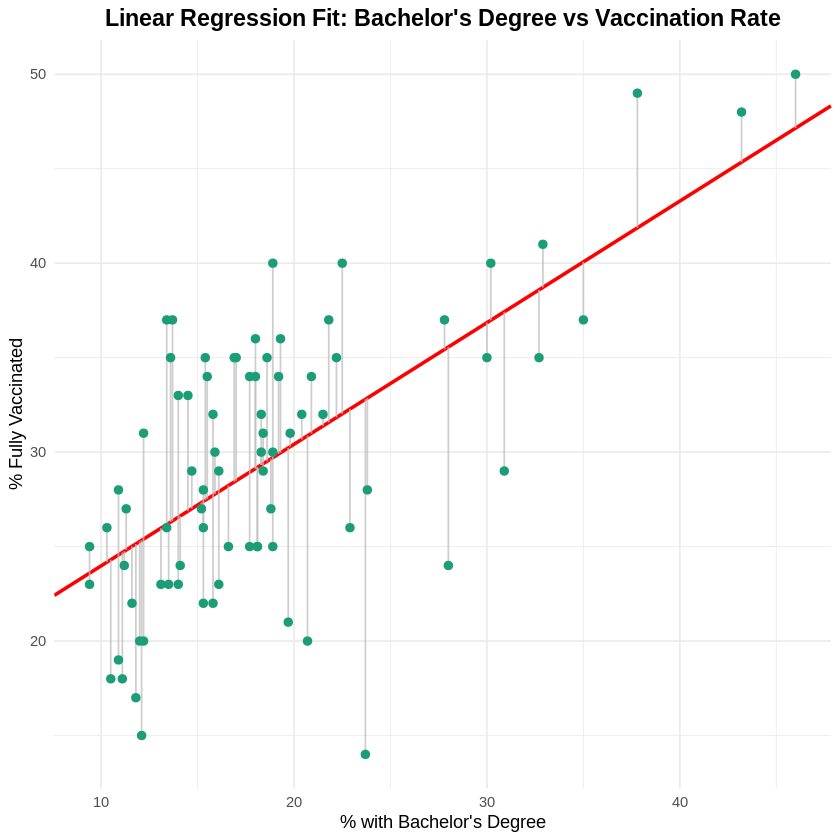

In [25]:
# Linear regression fit on training data
ggplot(train_data, aes(x = pct_bachelors, y = pct_fully_vaccinated)) +
  # Fitted regression line
  geom_abline(intercept = intcpt, slope = slp, colour = "red", size = 1) +

  # Residual segments: actual point to fitted value
  geom_segment(
    aes(
      x = pct_bachelors,
      xend = pct_bachelors,
      y = pct_fully_vaccinated,
      yend = fitted(lm_model_bac)
    ),
    colour = "grey",
    alpha = 0.75
  ) +

  # Actual data points
  geom_point(color = "#1b9e77", size = 2) +

  labs(
    title = "Linear Regression Fit: Bachelor's Degree vs Vaccination Rate",
    x = "% with Bachelor's Degree",
    y = "% Fully Vaccinated"
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold", size = 14)
  )


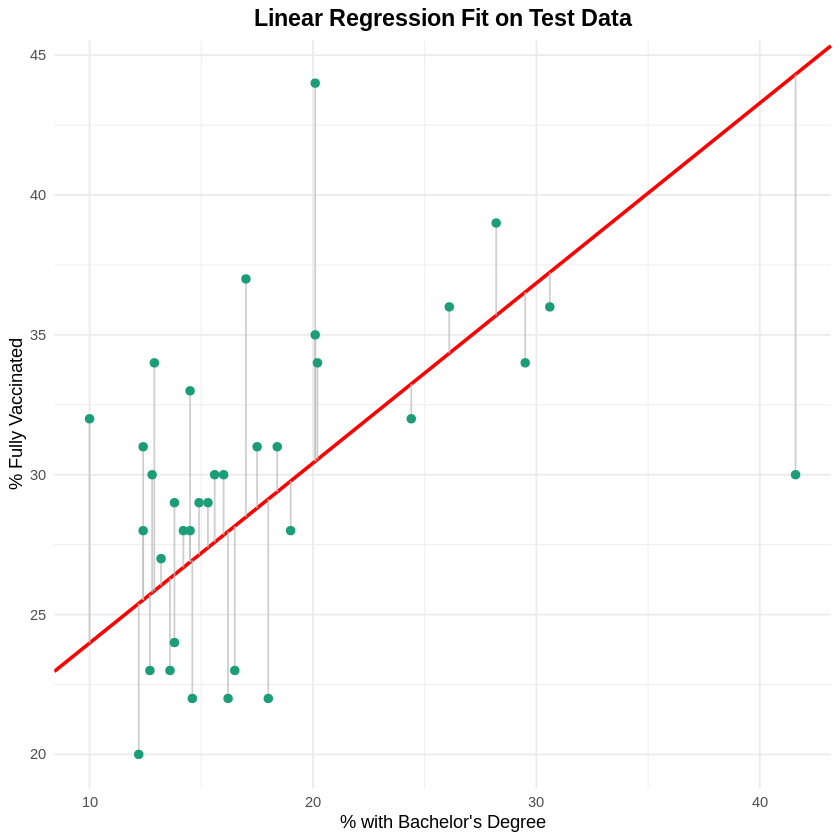

In [26]:
# Linear regression fit on test data
ggplot(test_data, aes(x = pct_bachelors, y = pct_fully_vaccinated)) +
  geom_abline(intercept = intcpt, slope = slp, colour = "red", size = 1) +
  geom_segment(
    aes(
      x = pct_bachelors,
      xend = pct_bachelors,
      y = pct_fully_vaccinated,
      yend = predict(lm_model_bac, newdata = test_data)
    ),
    colour = "grey",
    alpha = 0.75
  ) +
  geom_point(color = "#1b9e77", size = 2) +
  labs(
    title = "Linear Regression Fit on Test Data",
    x = "% with Bachelor's Degree",
    y = "% Fully Vaccinated"
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold", size = 14)
  )


#### Decision tree model

In [27]:
library(tree)

frmla <- pct_fully_vaccinated ~ pct_bachelors 

tree_model_bac   <- tree(frmla, data = train_data)


In [28]:
# View summary
summary(tree_model_bac  )


Regression tree:
tree(formula = frmla, data = train_data)
Number of terminal nodes:  5 
Residual mean deviance:  28.96 = 2172 / 75 
Distribution of residuals:
    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
-17.0300  -4.0830   0.8615   0.0000   3.9730   8.9730 

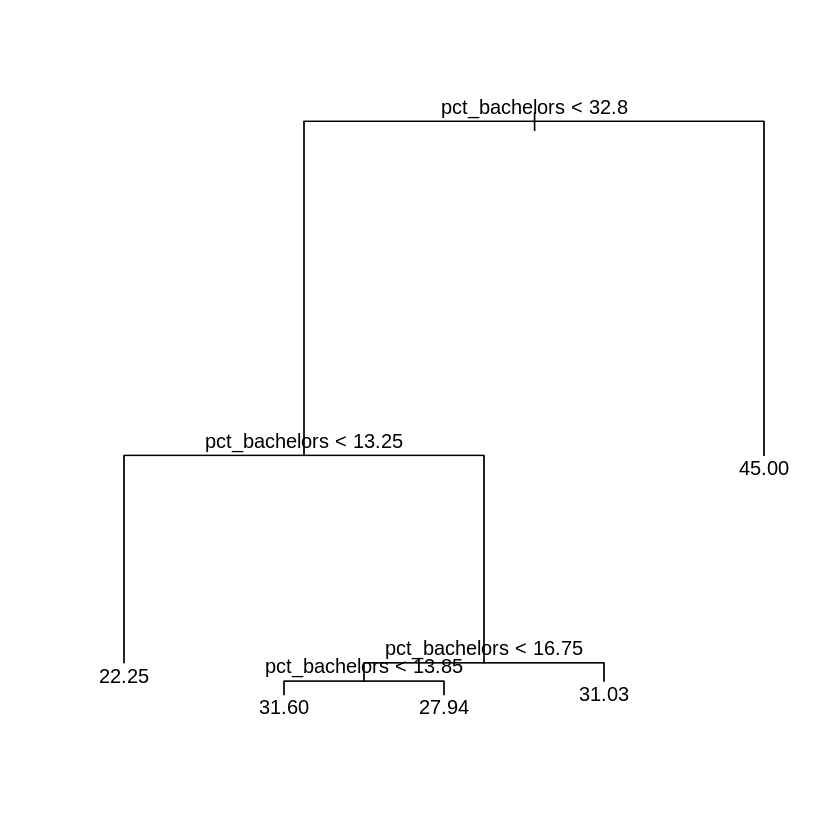

In [29]:
plot(tree_model_bac)
text(tree_model_bac)

In [30]:
# Predict linear regression and tree model
lm_pred_bac   <- predict(lm_model_bac, newdata = test_data)
tree_pred_bac <- predict(tree_model_bac, newdata = test_data)


Now lets compare the actual value with the predicted value for linear regression and decision tree and finally we will compare the level of accuracy of both models. We will also plot to see for both models.

In [31]:
results_bac <- data.frame(
  actual = test_data$pct_fully_vaccinated,
  lm_pred = lm_pred_bac,
  tree_pred = tree_pred_bac
)
results_bac

,actual,lm_pred,tree_pred
,<dbl>,<dbl>,<dbl>
4,28,26.87766,27.94118
7,29,27.13507,27.94118
12,24,26.42718,31.60000
16,36,37.23857,31.02703
19,36,34.34266,31.02703
22,39,35.69409,31.02703
30,28,25.52623,22.25000
33,22,26.94201,27.94118
36,44,30.48145,31.02703


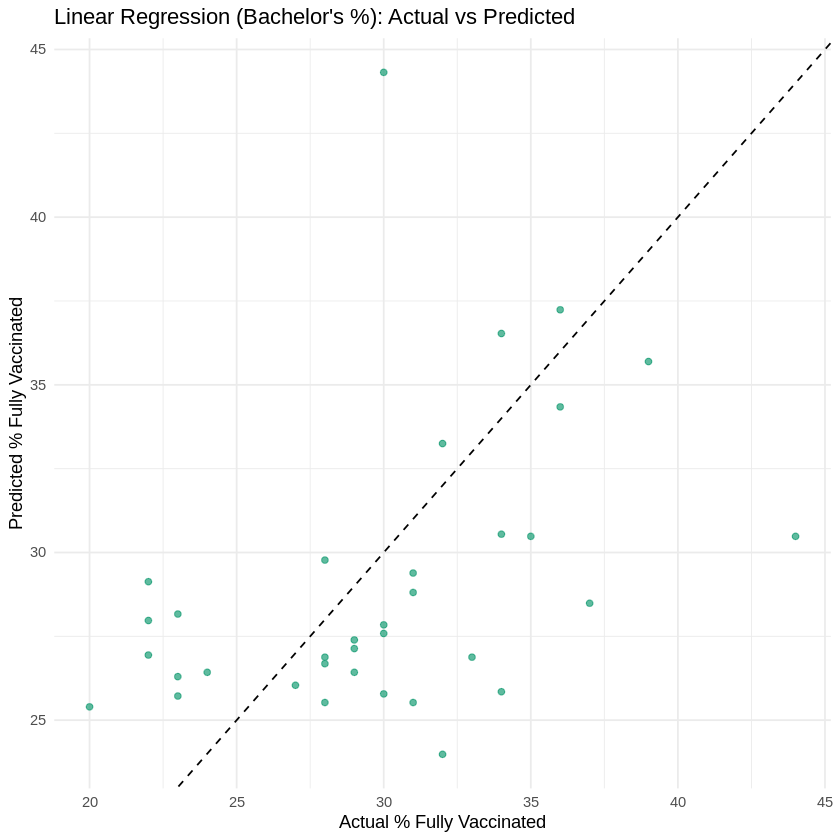

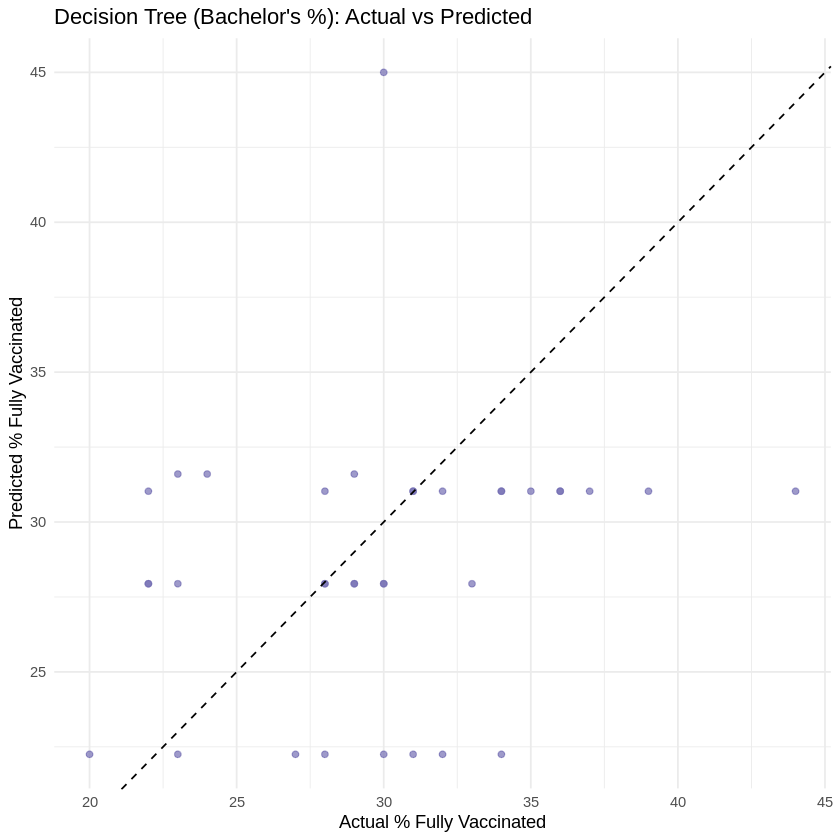

In [32]:
# Linear Regression
ggplot(results_bac, aes(x = actual, y = lm_pred)) +
  geom_point(color = "#1b9e77", alpha = 0.7) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed") +
  labs(
    title = "Linear Regression (Bachelor's %): Actual vs Predicted",
    x = "Actual % Fully Vaccinated",
    y = "Predicted % Fully Vaccinated"
  ) +
  theme_minimal()

# Decision Tree
ggplot(results_bac, aes(x = actual, y = tree_pred)) +
  geom_point(color = "#7570b3", alpha = 0.7) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed") +
  labs(
    title = "Decision Tree (Bachelor's %): Actual vs Predicted",
    x = "Actual % Fully Vaccinated",
    y = "Predicted % Fully Vaccinated"
  ) +
  theme_minimal()


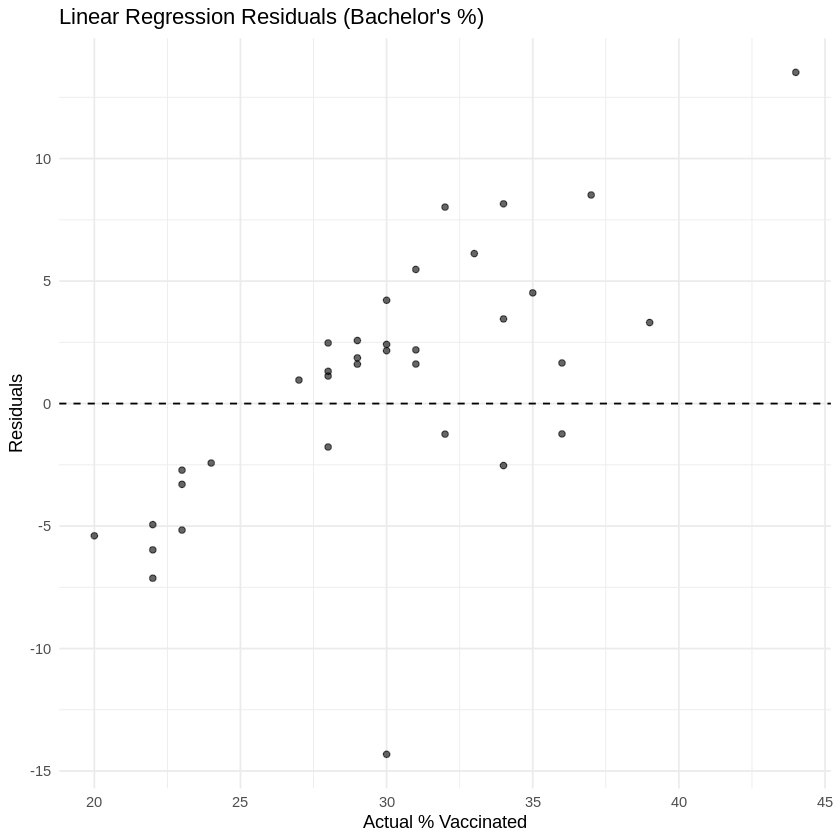

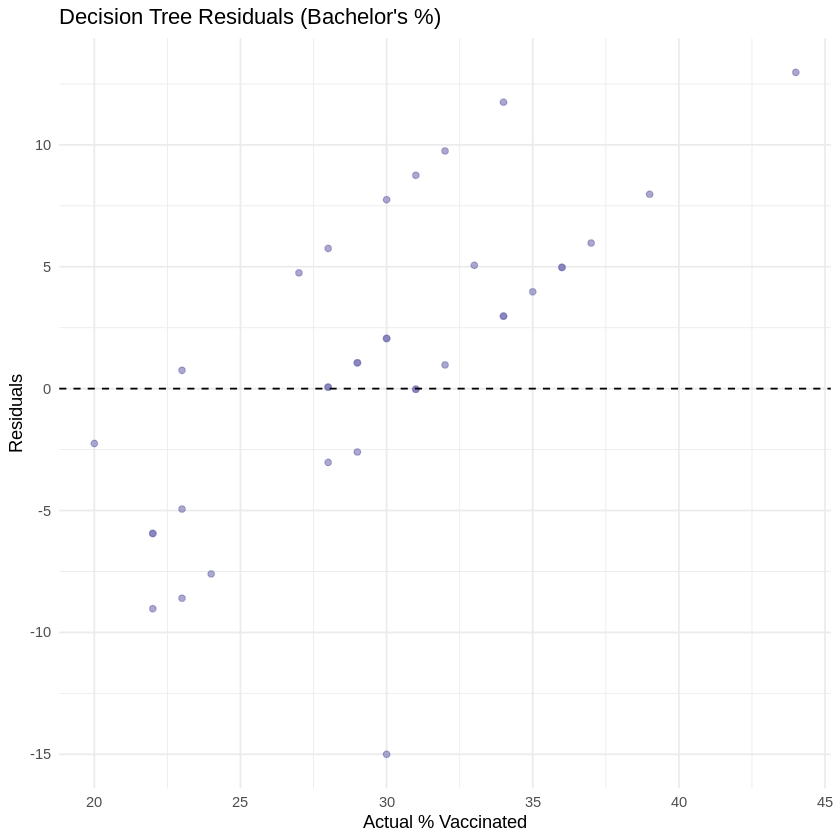

In [33]:
# Linear residuals
lm_res_bac <- results_bac$actual - results_bac$lm_pred

ggplot(data.frame(actual = results_bac$actual, residual = lm_res_bac),
       aes(x = actual, y = residual)) +
  geom_point(alpha = 0.6) +
  geom_hline(yintercept = 0, linetype = "dashed") +
  labs(
    title = "Linear Regression Residuals (Bachelor's %)",
    x = "Actual % Vaccinated",
    y = "Residuals"
  ) +
  theme_minimal()

# Tree residuals
tree_res_bac <- results_bac$actual - results_bac$tree_pred

ggplot(data.frame(actual = results_bac$actual, residual = tree_res_bac),
       aes(x = actual, y = residual)) +
  geom_point(alpha = 0.6, color = "#7570b3") +
  geom_hline(yintercept = 0, linetype = "dashed") +
  labs(
    title = "Decision Tree Residuals (Bachelor's %)",
    x = "Actual % Vaccinated",
    y = "Residuals"
  ) +
  theme_minimal()


From the plot, linear regression seems to show a stronger prediction than decision tree. Lets compare the Rsquared values of both models.

In [34]:
install.packages("Metrics")
library(Metrics)

lm_rmse_bac <- rmse(results_bac$actual, results_bac$lm_pred)
lm_r2_bac <- 1 - sum((results_bac$actual - results_bac$lm_pred)^2) / sum((results_bac$actual - mean(results_bac$actual))^2)

tree_rmse_bac <- rmse(results_bac$actual, results_bac$tree_pred)
tree_r2_bac <- 1 - sum((results_bac$actual - results_bac$tree_pred)^2) / sum((results_bac$actual - mean(results_bac$actual))^2)

cat("Linear Model (Bachelor's) - RMSE:", round(lm_rmse_bac, 2), "R²:", round(lm_r2_bac, 3), "\n")
cat("Decision Tree (Bachelor's) - RMSE:", round(tree_rmse_bac, 2), "R²:", round(tree_r2_bac, 3), "\n")


Updating HTML index of packages in '.Library'
Making 'packages.html' ... done

Attaching package: ‘Metrics’

The following objects are masked from ‘package:caret’:

    precision, recall



Linear Model (Bachelor's) - RMSE: 5.25 R²: 0.027 
Decision Tree (Bachelor's) - RMSE: 6.25 R²: -0.378 


for linear regression RMSE ≈ 5.25 means that, on average, the model’s predictions are off by about 5.25 percentage points.

R² ≈ 0.03 means the model explains only ~3% of the variation in vaccination rates.
This a low score which indicates that bachelor’s degree alone isn’t capturing enough variability across counties — at least not in a linear way.

Decision Tree

For decision tree RMSE ≈ 6.25 is worse than the linear model.

R² is negative (-0.378), which means the tree performs worse than simply predicting the mean for all counties.
This suggests the tree likely overfit on the training set but failed to generalize with just one variable.

## Step 6: Effective use of Visualizations (EDA and vetting) and development of Key Visualizations of Final Results (10 points)

Build up your **key** visual story elements!

Add more cells (`Insert > Insert Cell Below`) if you want additional cells.

Lets see some key visuals, first, we will look at educational attainments among counties.

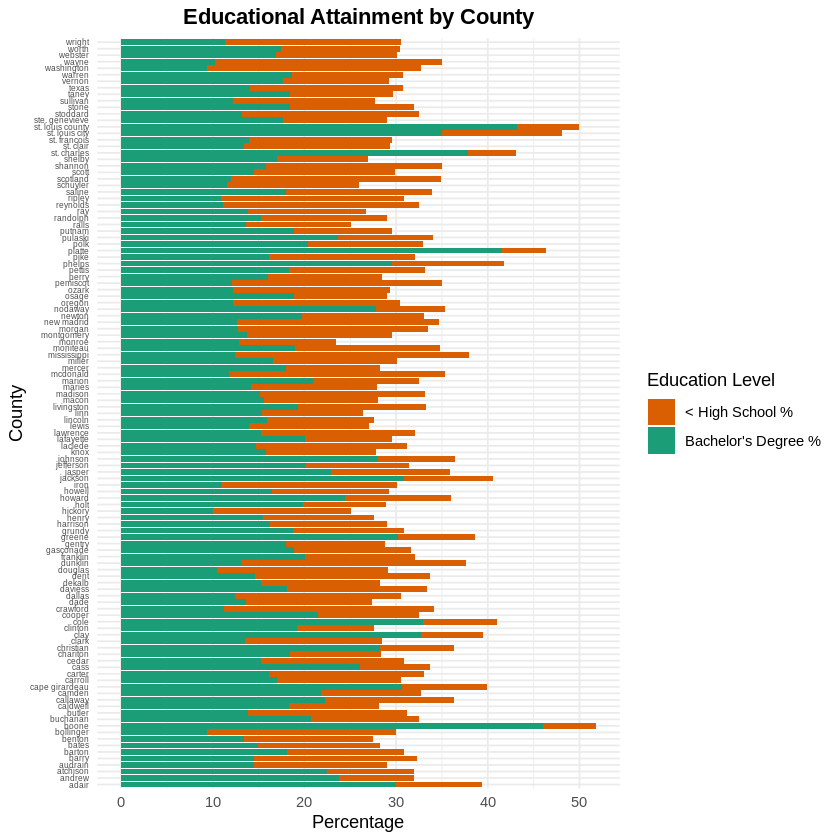

In [49]:
# Create two separate data frames and bind them together
bachelors_df <- df %>%
  select(county, pct_bachelors) %>%
  mutate(variable = "Bachelor's Degree %",
         value = pct_bachelors) %>%
  select(county, variable, value)

less_than_hs_df <- df %>%
  select(county, pct_less_than_high_school) %>%
  mutate(variable = "< High School %",
         value = pct_less_than_high_school) %>%
  select(county, variable, value)

# Combine both into one
edu_long <- rbind(bachelors_df, less_than_hs_df)
head(edu_long)

ggplot(edu_long, aes(x = county, y = value, fill = variable)) +
  geom_bar(stat = "identity") +
  coord_flip() +
  labs(
    title = "Educational Attainment by County",
    x = "County",
    y = "Percentage",
    fill = "Education Level"
  ) +
  scale_fill_manual(values = c(
    "Bachelor's Degree %" = "#1b9e77",
    "< High School %" = "#d95f02"
  )) +
  theme_minimal() +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    axis.text.y = element_text(size = 5)
  )


Boone county seems to be top-ranking in educational attainments in Missouri, Next we are going to get all the us county polygons and narrow it down to Missouri counties so as to visualise the extent of COVID-19 vaccination accross counties. I will use the embedded U.S counties data in the maps package in R.

long,lat,group,order,region,subregion
<dbl>,<dbl>,<dbl>,<int>,<chr>,<chr>
-92.67592,40.35342,1450,43832,missouri,adair
-92.33215,40.35342,1450,43833,missouri,adair
-92.33215,40.31331,1450,43834,missouri,adair
-92.33215,40.04402,1450,43835,missouri,adair
-92.84208,40.03829,1450,43836,missouri,adair
-92.84208,40.34769,1450,43837,missouri,adair


long,lat,group,order,region,subregion,pct_fully_vaccinated,pct_one_dose,pct_bachelors,pct_less_than_high_school,median_income,pct_disability,obesity_rate,smoking_prevalence
<dbl>,<dbl>,<dbl>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
-92.67592,40.35342,1450,43832,missouri,adair,35,39,30,9.4,19948,16.4,28.2,23.3
-92.33215,40.35342,1450,43833,missouri,adair,35,39,30,9.4,19948,16.4,28.2,23.3
-92.33215,40.31331,1450,43834,missouri,adair,35,39,30,9.4,19948,16.4,28.2,23.3
-92.33215,40.04402,1450,43835,missouri,adair,35,39,30,9.4,19948,16.4,28.2,23.3
-92.84208,40.03829,1450,43836,missouri,adair,35,39,30,9.4,19948,16.4,28.2,23.3
-92.84208,40.34769,1450,43837,missouri,adair,35,39,30,9.4,19948,16.4,28.2,23.3


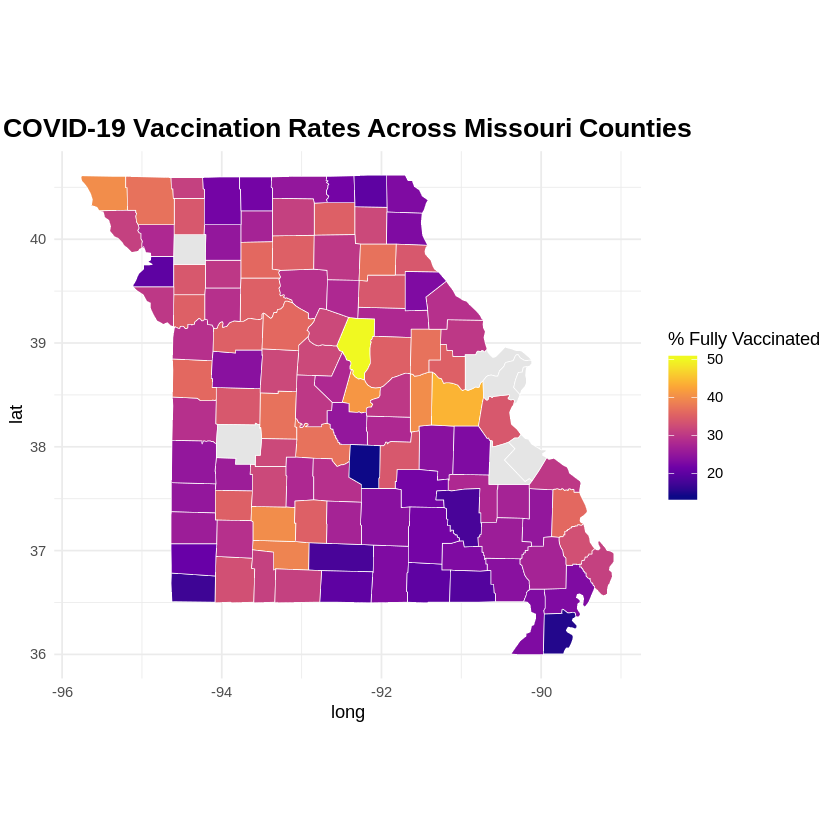

In [35]:

# 1. Get all US county polygons
county_map <- map_data("county")

# 2. Filter to Missouri
mo_county_map <- county_map %>%
  filter(region == "missouri")

# Preview the structure
head(mo_county_map)

df <- df %>%
  mutate(county = tolower(trimws(county)))

mo_county_map <- mo_county_map %>%
  mutate(subregion = tolower(trimws(subregion)))

# left-join both datasets

mo_map_data <- mo_county_map %>%
  left_join(df, by = c("subregion" = "county"))
head(mo_map_data)

ggplot(mo_map_data, aes(long, lat, group = group, fill = pct_fully_vaccinated)) +
  geom_polygon(color = "white", size = 0.2) +
  coord_fixed(1.3) +
  scale_fill_viridis_c(option = "plasma", na.value = "grey90") +
  labs(
    title = "COVID-19 Vaccination Rates Across Missouri Counties",
    fill = "% Fully Vaccinated"
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(hjust = 0.5, size = 16, face = "bold")
  )


From the maps above, Boone county still semms to be taking the lead on vaccinations. Finally, lets visualise the to 10 counties with bachelors degree education and compare it with their vaccinations.

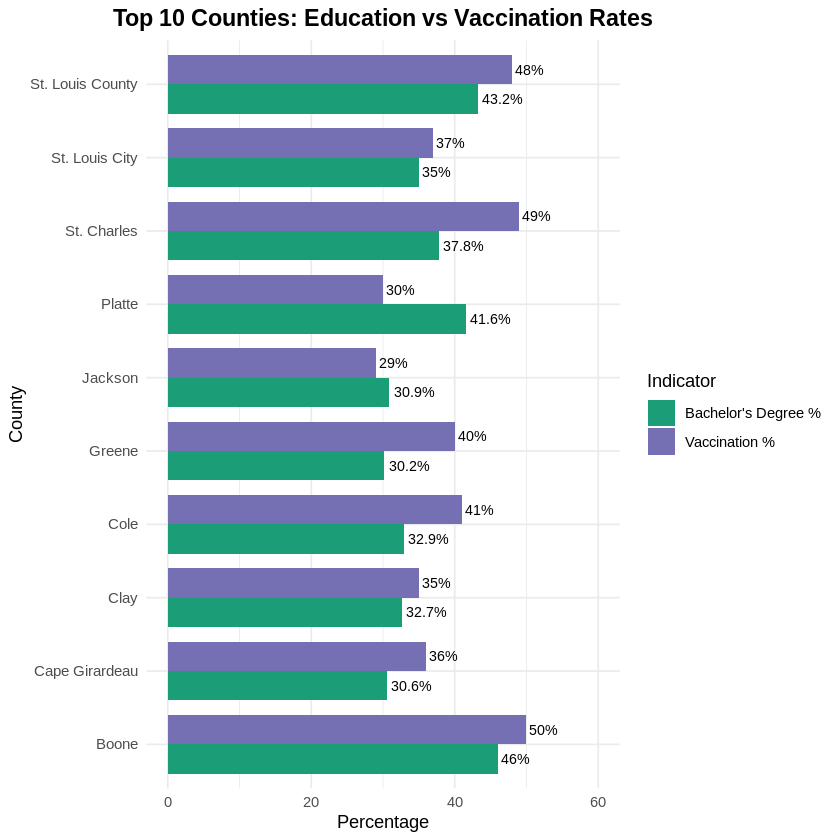

In [33]:


# Take top 10 counties by bachelor's degree %
top10_edu_vax <- df %>%
  arrange(desc(pct_bachelors)) %>%
  head(10)

# Reshape manually to long format
bachelors_df <- top10_edu_vax %>%
  select(county, pct_bachelors) %>%
  mutate(variable = "Bachelor's Degree %", value = pct_bachelors) %>%
  select(county, variable, value)

vax_df <- top10_edu_vax %>%
  select(county, pct_fully_vaccinated) %>%
  mutate(variable = "Vaccination %", value = pct_fully_vaccinated) %>%
  select(county, variable, value)

edu_vax_long <- rbind(bachelors_df, vax_df)

edu_vax_long

# Plot grouped bar chart
ggplot(edu_vax_long, aes(x = county, y = value, fill = variable)) +
  geom_bar(stat = "identity", position = "dodge", width = 0.8) +
  coord_flip() +
  geom_text(aes(label = paste0(round(value, 1), "%")),
            position = position_dodge(width = 0.8),
            hjust = -0.1, size = 3) +
  labs(
    title = "Top 10 Counties: Education vs Vaccination Rates",
    x = "County",
    y = "Percentage",
    fill = "Indicator"
  ) +
  scale_fill_manual(values = c(
    "Bachelor's Degree %" = "#1b9e77",
    "Vaccination %" = "#7570b3"
  )) +
  theme_minimal() +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold", size = 14),
    axis.text.y = element_text(size = 9)
  ) +
  ylim(0, max(edu_vax_long$value) * 1.2)


## Step 7: Communicate the Story to your intended audience using visualizations and narrative  (15 points)


Briefly describe the story you are trying to tell with these data. Make sure to address the "So What!" aspect of the investigation.  Why did you choose the topic for analysis? What made it unique? Why would you consider it a data science project?



This analysis investigates how educational attainment influences COVID-19 vaccination rates across Missouri counties. The results show that education correlates strongly with vaccine uptake — counties with more college-educated residents show significantly higher vaccination rates.

The findings highlight the importance of education and information access in shaping public-health behaviors. Policymakers can use this insight to design targeted outreach and literacy programs in counties with lower educational attainment, improving public-health outcomes and resilience to future pandemics.

The “So What”:
Education affects more than income — it affects trust, information access, and health decision-making. Recognizing education as a predictor of vaccination helps identify areas needing additional communication and outreach.


## Step 8: Connect your workflow / process to the DSA-Project Life Cycle  (15 points)
- List **each** stage and then briefly discuss how important details from the [DSA-PLC](../../module1/resources/DSA-ProjectLifecycle-slidedeck.pdf) played a role in your story development.
- Use markdown to provide this overview below:
<hr/>

<h1 align="center"><u>DSA-Project Life Cycle Discussion</u></h1>



| DSA-PLC Stage                       | Application                                                                           |
| ----------------------------------- | ------------------------------------------------------------------------------------- |
| **1 – Project Definition, Requirements, & Expectations**                  | Framed the problem: relationship between education and vaccination rates.             |
| **2 – Data acquisition, governance, curation and source code management**    | Used provided Missouri County dataset and built-in maps U.S county dataset; confirmed validity and completeness.           |
| **3 – Data shaping and carpentry**                 | Selected relevant variables, cleaned NAs, standardized data.                          |
| **4 – EDA and visualisation**                         | Visualized distributions both univariate and multivariate and correlations between education and vaccination.          |
| **5 – Model Planning**              | Used correlation, recursive feature selection and Random forest method. Also used Linear regression and decision tree models.                                          |
| **6 – Model Building & Validation** | Trained and evaluated models using R² and RMSE.                                       |
| **7 – Data story/product development and reporting**   | Created plots and summaries tailored to public-health audiences.                      |
| **8 – Deployment & Monitoring**     | Insights can guide outreach in counties with low education and low vaccination rates. |


## Step 9: Post the Story to Canvas


Final step, **POST your most compelling visual and provide a brief description (absrtact) of what it conveys, to the course Canvas Site).** Feel free to review and provide feedback. 

You might consider posting some aspects during the process. Your classmates will be vital providers of feedback in this process. Utilize them.

# Save your notebook, then `File > Close and Halt`